<a href="https://colab.research.google.com/github/guigadesouza11/Comunica-es-Moveis/blob/main/Simula%C3%A7%C3%A3o_de_probabilidade_de_interrup%C3%A7%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Potência média Rayleigh: 1.0019114073850495
Potência média Rice:     0.9995915068838368


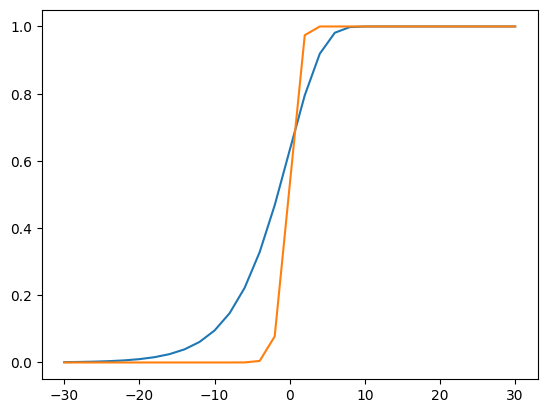

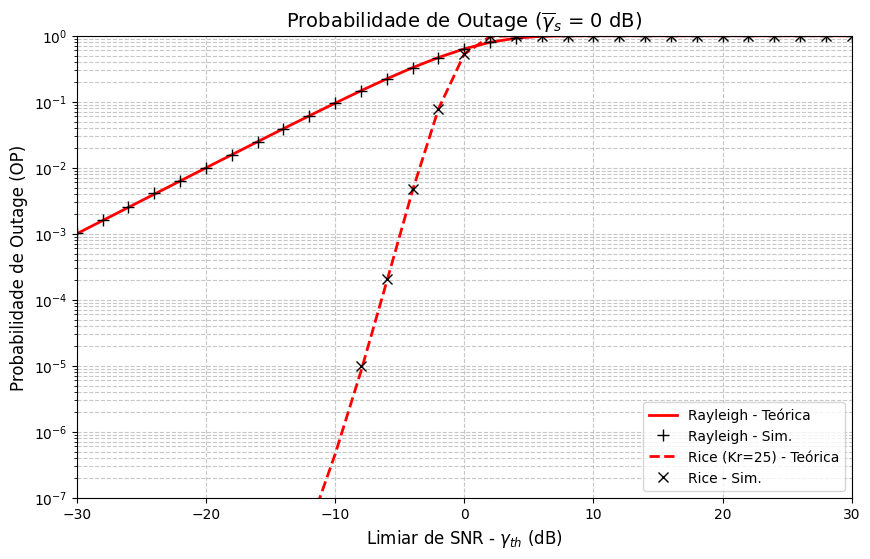

In [2]:
import numpy as np
from scipy.special import erfc
import matplotlib.pyplot as plt
from scipy.stats import ncx2

N_t = 10**6
snr_media_dB = 0
snr_media_linear = 10**(snr_media_dB/10)

vetor_de_limiares = np.arange(-30, 31, 2)
vetor_de_limiares_linear = 10**(vetor_de_limiares/10)

#rayleigh
desvio_padrao_rayleigh = np.sqrt(1/2)
x_rayleigh = np.random.normal(0, desvio_padrao_rayleigh, size= N_t)
y_rayleigh = np.random.normal(0, desvio_padrao_rayleigh, size= N_t)
beta_quadrado_rayleigh = x_rayleigh**2 + y_rayleigh**2
snr_simbolo_rayleigh = snr_media_linear * beta_quadrado_rayleigh

#rice
kr = 25
desvio_padrao_rice = np.sqrt(1/(2*(kr+1)))
media_rice = np.sqrt(kr/(kr+1))

x_rice = np.random.normal(media_rice, desvio_padrao_rice, size= N_t)
y_rice = np.random.normal(0, desvio_padrao_rice, size= N_t)

beta_quadrado_rice = x_rice**2 + y_rice**2
snr_simbolo_rice = snr_media_linear * beta_quadrado_rice

op_simulada_rayleigh = []
op_simulada_rice = []

for limiar in vetor_de_limiares_linear:
  N_s_rayleigh = np.sum(snr_simbolo_rayleigh <= limiar)
  op_simulada_rayleigh.append(N_s_rayleigh / N_t)
  N_s_rice = np.sum(snr_simbolo_rice <= limiar)
  op_simulada_rice.append(N_s_rice / N_t)

op_teorica_rayleigh = 1 - np.exp(-vetor_de_limiares_linear / snr_media_linear)
op_teorica_rice = ncx2.cdf(
    2 * (kr + 1) * vetor_de_limiares_linear / snr_media_linear, df=2, nc=2 * kr
)

plt.plot(vetor_de_limiares, op_teorica_rayleigh, label='Rayleigh')
plt.plot(vetor_de_limiares, op_teorica_rice, label='Rice')

print("Potência média Rayleigh:", np.mean(beta_quadrado_rayleigh))
print("Potência média Rice:    ", np.mean(beta_quadrado_rice))

plt.figure(figsize=(10, 6))

plt.semilogy(
    vetor_de_limiares,
    op_teorica_rayleigh,
    'r-',
    linewidth=2,
    label='Rayleigh - Teórica',
)
plt.semilogy(
    vetor_de_limiares,
    op_simulada_rayleigh,
    'k+',
    markersize=8,
    label='Rayleigh - Sim.',
)

plt.semilogy(
    vetor_de_limiares,
    op_teorica_rice,
    'r--',
    linewidth=2,
    label=f'Rice (Kr={kr}) - Teórica',
)
plt.semilogy(
    vetor_de_limiares, op_simulada_rice, 'kx', markersize=7, label='Rice - Sim.'
)

plt.xlabel(r'Limiar de SNR - $\gamma_{th}$ (dB)', fontsize=12)
plt.ylabel('Probabilidade de Outage (OP)', fontsize=12)
plt.title(
    rf'Probabilidade de Outage ($\overline{{\gamma}}_s$ = {snr_media_dB} dB)',
    fontsize=14,
)
plt.ylim(1e-7, 1)
plt.xlim(-30, 30)
plt.grid(True, which='both', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.show()
